In [2]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"
response = requests.get(url, timeout=15)
response.raise_for_status()

response.encoding = "utf-8"
soup = BeautifulSoup(response.text, "html.parser")

rating_map = {
    "One": 1, "Two": 2, "Three": 3,
    "Four": 4, "Five": 5
}

books = []

for card in soup.select("article.product_pod"):
    title = card.select_one("h3 a")["title"]
    price_text = card.select_one(".price_color").get_text(strip=True)
    price = float(price_text.replace("£", ""))

    rating_classes = card.select_one(".star-rating").get("class", [])
    rating = next(
        (rating_map[c] for c in rating_classes if c in rating_map),
        None
    )

    books.append({
        "Title": title,
        "Price": price,
        "Rating": rating
    })

df = pd.DataFrame(books)

print("Books collected:", len(df))
print(df.head())

best = (
    df[df["Rating"] == 5]
    .sort_values("Price")
    .head(5)
)

display(best)
  

Books collected: 20
                                   Title  Price  Rating
0                   A Light in the Attic  51.77       3
1                     Tipping the Velvet  53.74       1
2                             Soumission  50.10       1
3                          Sharp Objects  47.82       4
4  Sapiens: A Brief History of Humankind  54.23       5


,Title,Price,Rating
12,Set Me Free,17.46,5
14,Rip it Up and Start Again,35.02,5
13,Scott Pilgrim's Precious Little Life (Scott Pi...,52.29,5
4,Sapiens: A Brief History of Humankind,54.23,5


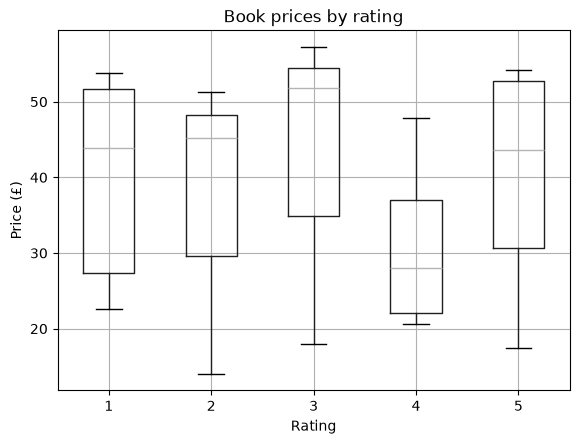

In [3]:
import matplotlib.pyplot as plt

df.boxplot(column="Price", by="Rating")
plt.title("Book prices by rating")
plt.suptitle("")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.show()